# EmotionSense: DAiSEE Image Preprocessing Pipeline

Turns the raw **DAiSEE** dataset (videos + video-level labels) into a clean, label-aligned, model-ready image dataset.

**Pipeline**
1. Install missing packages, auto-detect the dataset
2. Load and clean the label CSVs (Boredom, Engagement, Confusion, Frustration; levels 0-3)
3. Extract evenly spaced frames from each video (resumable)
4. Align frames with labels via `ClipID`
5. Quality checks (unreadable, blur, brightness)
6. Label distribution and sample visualisation
7. Face detection + crop, resize to 224x224 (stored as `uint8`)
8. Subject-independent train / validation / test splits
9. Class weights, saved `.npz` arrays and manifests, optional PyTorch `Dataset`

**Runs out of the box:** without real data it uses a synthetic demo dataset (clearly announced in Section 3), so *Run All* always works. With real DAiSEE found or configured, it uses that instead.

## 1. Install / import libraries

Missing packages are installed automatically.

In [1]:
import sys, subprocess, importlib, os, re, json, random
from pathlib import Path

def _ensure(import_name, pip_name):
    try:
        importlib.import_module(import_name)
    except ImportError:
        print(f"Installing {pip_name} ...")
        try:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])
        except Exception as exc:
            print(f"Could not install {pip_name}: {exc}")

for _imp, _pip in [("numpy", "numpy"), ("pandas", "pandas"), ("matplotlib", "matplotlib"),
                   ("cv2", "opencv-python-headless"), ("tqdm", "tqdm")]:
    _ensure(_imp, _pip)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

try:
    from IPython.display import display
except ImportError:
    display = print
try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(it, **kwargs):
        return it

print("Imports completed. OpenCV version:", cv2.__version__)

Imports completed. OpenCV version: 5.0.0


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Configuration

By default the notebook **searches for DAiSEE automatically** (current folder, `/content`, Google Drive, Kaggle inputs, home folder). If it cannot find it, set `MANUAL_DATASET_ROOT` to the folder that contains `Labels/` and `DataSet/`, for example:

```python
MANUAL_DATASET_ROOT = Path('/content/drive/MyDrive/DAiSEE')   # Colab + Drive
MANUAL_DATASET_ROOT = Path(r'D:/Datasets/DAiSEE')             # Windows
```

On Colab, mount Drive first:
```python
from google.colab import drive
drive.mount('/content/drive')
```

Expected layout:
```text
DAiSEE/
├── DataSet/
│   ├── Train/<subject_id>/<clip_id>/<clip_id>.avi
│   ├── Validation/...
│   └── Test/...
└── Labels/
    ├── TrainLabels.csv
    ├── ValidationLabels.csv
    └── TestLabels.csv
```

**No edits are needed to run it.** If real DAiSEE is not found, the notebook builds a tiny synthetic demo dataset and runs the full pipeline on it, so every cell works and shows output. Set `AUTO_DEMO_FALLBACK = False` to disable this, or `USE_DEMO_DATA = True` to force the demo.
Outputs go to `./emotionsense_outputs` (real data) or `./emotionsense_outputs_demo` (demo).

In [2]:
MANUAL_DATASET_ROOT = None        # e.g. Path('/content/drive/MyDrive/DAiSEE')
USE_DEMO_DATA = False             # True = always use the small synthetic demo dataset
AUTO_DEMO_FALLBACK = True         # if real DAiSEE is not found, run on the synthetic demo so the notebook still works

LABEL_COLUMNS = ["Boredom", "Engagement", "Confusion", "Frustration"]
FRAMES_PER_VIDEO = 5              # evenly spaced frames taken from each clip
MAX_VIDEOS_PER_SPLIT = 100        # None = use every video (about 9,000 in DAiSEE)
IMAGE_SIZE = (224, 224)           # (width, height)
DETECT_FACES = True               # crop to the detected face (falls back to the full frame)
FACE_PADDING = 0.20               # extra margin around the detected face
SEED = 42

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
VIDEO_EXTENSIONS = {".avi", ".mp4", ".mov", ".mkv"}

OUTPUT_DIR = Path("./emotionsense_outputs")
EXTRACTED_FRAMES_DIR = OUTPUT_DIR / "extracted_frames"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)

DATA_READY = True

def stop(msg):
    """Mark the pipeline as stopped; later cells will skip instead of crashing."""
    global DATA_READY
    DATA_READY = False
    print("STOPPED:", msg)

print("Configuration loaded. Outputs will go to:", OUTPUT_DIR.resolve())

Configuration loaded. Outputs will go to: /tmp/claude-0/-home-claude/34ea60f0-0a28-5185-9fa7-6f370c5041d0/scratchpad/run/emotionsense_outputs


## 3. Locate the dataset

In [3]:
def make_demo_dataset(root):
    """Tiny synthetic DAiSEE-like dataset (random frames, random labels) for testing only."""
    rng = np.random.RandomState(0)
    plan = {"Train": 6, "Validation": 2, "Test": 2}
    rows = {"Train": [], "Validation": [], "Test": []}
    sid = 110001
    for split_name, n_subjects in plan.items():
        for _ in range(n_subjects):
            for c in range(2):
                clip = f"{sid}{1000 + c}"
                folder = root / "DataSet" / split_name / str(sid) / clip
                folder.mkdir(parents=True, exist_ok=True)
                writer = cv2.VideoWriter(str(folder / f"{clip}.avi"),
                                         cv2.VideoWriter_fourcc(*"MJPG"), 10, (160, 120))
                for t in range(12):
                    base = np.linspace(40, 140, 160, dtype=np.uint8)[None, :, None].repeat(120, 0).repeat(3, 2)
                    frame = base + rng.randint(0, 25, (120, 160, 3), dtype=np.uint8)
                    cv2.ellipse(frame, (80, 60), (28 + t % 4, 36), 0, 0, 360, (170, 190, 225), -1)
                    cv2.circle(frame, (70, 52), 3, (30, 30, 30), -1)
                    cv2.circle(frame, (90, 52), 3, (30, 30, 30), -1)
                    cv2.ellipse(frame, (80, 74), (9, 4), 0, 0, 180, (60, 60, 160), 2)
                    writer.write(frame)
                writer.release()
                rows[split_name].append({"ClipID": f"{clip}.avi",
                                         "Boredom": int(rng.randint(0, 4)),
                                         "Engagement": int(rng.randint(0, 4)),
                                         "Confusion ": int(rng.randint(0, 4)),
                                         "Frustration ": int(rng.randint(0, 4))})
            sid += 1
    (root / "Labels").mkdir(parents=True, exist_ok=True)
    for split_name, r in rows.items():
        pd.DataFrame(r).to_csv(root / "Labels" / f"{split_name}Labels.csv", index=False)
    print("Demo dataset created at:", root.resolve())


def find_label_dir():
    if MANUAL_DATASET_ROOT is not None:
        roots = [Path(MANUAL_DATASET_ROOT)]
    else:
        roots = [Path.cwd(), Path("./DAiSEE"), Path("/content"), Path("/content/drive/MyDrive"),
                 Path("/kaggle/input"), Path("/kaggle/working"), Path.home()]
    skip = {"sample_data", "__pycache__", "demo_DAiSEE", "emotionsense_outputs", "emotionsense_outputs_demo"}
    seen = set()
    for root in roots:
        try:
            if not root.exists():
                continue
            root = root.resolve()
            if root in seen:
                continue
            seen.add(root)
            base_depth = len(root.parts)
            for dirpath, dirnames, filenames in os.walk(root):
                if len(Path(dirpath).parts) - base_depth >= 5:
                    dirnames[:] = []
                    continue
                dirnames[:] = [d for d in dirnames if not d.startswith(".") and d not in skip]
                if any(f.lower().endswith("labels.csv") for f in filenames):
                    return Path(dirpath)
        except (PermissionError, OSError):
            continue
    return None


IS_DEMO = False
label_dir_found = None if USE_DEMO_DATA else find_label_dir()
if label_dir_found is None and (USE_DEMO_DATA or AUTO_DEMO_FALLBACK):
    make_demo_dataset(Path("./demo_DAiSEE"))
    MANUAL_DATASET_ROOT = Path("./demo_DAiSEE")
    label_dir_found = find_label_dir()
    IS_DEMO = True
    OUTPUT_DIR = Path("./emotionsense_outputs_demo")
    EXTRACTED_FRAMES_DIR = OUTPUT_DIR / "extracted_frames"
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    print("=" * 70)
    print("REAL DAiSEE DATA NOT FOUND -> RUNNING ON A SMALL SYNTHETIC DEMO DATASET.")
    print("The numbers and images below are NOT real results. To use your data,")
    print("set MANUAL_DATASET_ROOT in Section 2 (folder containing Labels/ and DataSet/).")
    print("=" * 70)

if label_dir_found is None:
    stop(
        "DAiSEE label CSVs (e.g. TrainLabels.csv) were not found.\n"
        "  -> Set MANUAL_DATASET_ROOT in Section 2 to the folder containing Labels/ and DataSet/.\n"
        "  -> On Colab: mount Google Drive (or upload the dataset) first.\n"
        "  -> Or set USE_DEMO_DATA = True to test the pipeline with synthetic data."
    )
else:
    LABEL_DIR = label_dir_found
    DATASET_ROOT = LABEL_DIR.parent if LABEL_DIR.name.lower() == "labels" else LABEL_DIR
    print("Label folder:   ", LABEL_DIR.resolve())
    print("Dataset root:   ", DATASET_ROOT.resolve())

Demo dataset created at: /tmp/claude-0/-home-claude/34ea60f0-0a28-5185-9fa7-6f370c5041d0/scratchpad/run/demo_DAiSEE
REAL DAiSEE DATA NOT FOUND -> RUNNING ON A SMALL SYNTHETIC DEMO DATASET.
The numbers and images below are NOT real results. To use your data,
set MANUAL_DATASET_ROOT in Section 2 (folder containing Labels/ and DataSet/).
Label folder:    /tmp/claude-0/-home-claude/34ea60f0-0a28-5185-9fa7-6f370c5041d0/scratchpad/run/demo_DAiSEE/Labels
Dataset root:    /tmp/claude-0/-home-claude/34ea60f0-0a28-5185-9fa7-6f370c5041d0/scratchpad/run/demo_DAiSEE


## 4. Discover videos and existing frames

The split is inferred from folder names. In DAiSEE the first 6 digits of a `ClipID` identify the **person**, which we need for subject-independent splitting.

In [4]:
if DATA_READY:
    def infer_split(path, root):
        try:
            parts = Path(path).relative_to(root).parts
        except ValueError:
            parts = Path(path).parts
        for part in parts[:-1]:
            p = part.lower()
            if p in ("train", "training"):
                return "train"
            if p in ("validation", "val", "valid"):
                return "validation"
            if p == "test":
                return "test"
        return "unknown"


    def clip_id_from_path(path):
        match = re.search("[0-9]{10}", Path(path).stem)
        if match is None:
            match = re.search("[0-9]{10}", str(path))
        return match.group(0) if match else None


    out_resolved = str(OUTPUT_DIR.resolve())
    video_paths, existing_frame_paths = [], []
    for p in DATASET_ROOT.rglob("*"):
        try:
            if not p.is_file() or out_resolved in str(p.resolve()):
                continue
        except OSError:
            continue
        ext = p.suffix.lower()
        if ext in VIDEO_EXTENSIONS:
            video_paths.append(p)
        elif ext in IMAGE_EXTENSIONS and clip_id_from_path(p) is not None:
            existing_frame_paths.append(p)
    video_paths.sort()
    existing_frame_paths.sort()

    video_df = pd.DataFrame({
        "video_path": pd.Series([str(p) for p in video_paths], dtype="object"),
        "clip_id": pd.Series([clip_id_from_path(p) or p.stem for p in video_paths], dtype="object"),
        "split": pd.Series([infer_split(p, DATASET_ROOT) for p in video_paths], dtype="object"),
    })
    video_df["subject_id"] = video_df["clip_id"].astype(str).str[:6]

    print(f"Videos found:          {len(video_df):,}")
    print(f"Existing frames found: {len(existing_frame_paths):,}")

    if video_df.empty and not existing_frame_paths:
        stop(f"No videos or frame images found under {DATASET_ROOT.resolve()}. "
             "Check that the DataSet/ folder was extracted there.")
    else:
        if not video_df.empty:
            display(video_df.head())
            print(video_df["split"].value_counts().to_string())
else:
    print('Skipped: an earlier step could not complete (see the STOPPED message above).')

Videos found:          20
Existing frames found: 0


,video_path,clip_id,split,subject_id
0,/tmp/claude-0/-home-claude/34ea60f0-0a28-5185-...,1100091000,test,110009
1,/tmp/claude-0/-home-claude/34ea60f0-0a28-5185-...,1100091001,test,110009
2,/tmp/claude-0/-home-claude/34ea60f0-0a28-5185-...,1100101000,test,110010
3,/tmp/claude-0/-home-claude/34ea60f0-0a28-5185-...,1100101001,test,110010
4,/tmp/claude-0/-home-claude/34ea60f0-0a28-5185-...,1100011000,train,110001


split
train         12
test           4
validation     4


## 5. Load and clean the label CSVs

DAiSEE labels are **video-level** (one value per clip), levels 0-3. Column names can contain stray spaces (e.g. `Frustration `), so they are stripped. All frames from a clip inherit that clip's label.

In [5]:
if DATA_READY:
    parts = []
    for f in sorted(LABEL_DIR.glob("*.csv")):
        name = f.name.lower()
        if "label" not in name:
            continue
        if "train" in name:
            split_name = "train"
        elif "valid" in name or "val" in name:
            split_name = "validation"
        elif "test" in name:
            split_name = "test"
        else:
            split_name = "unknown"
        try:
            df = pd.read_csv(f)
        except Exception as exc:
            print("Could not read", f.name, "->", exc)
            continue
        df.columns = [str(c).strip() for c in df.columns]
        df["label_split"] = split_name
        parts.append(df)

    if not parts:
        stop(f"No readable label CSV files in {LABEL_DIR.resolve()}.")
    else:
        labels_df = pd.concat(parts, ignore_index=True)
        lower_map = {c.lower(): c for c in labels_df.columns}
        rename = {lower_map[c.lower()]: c for c in LABEL_COLUMNS + ["ClipID"] if c.lower() in lower_map}
        labels_df = labels_df.rename(columns=rename)
        missing = [c for c in LABEL_COLUMNS + ["ClipID"] if c not in labels_df.columns]
        if missing:
            stop(f"Label CSV is missing columns {missing}. Found: {labels_df.columns.tolist()}")
        else:
            labels_df["clip_id"] = (labels_df["ClipID"].astype(str).str.strip()
                                    .str.replace(r"\.[A-Za-z0-9]+$", "", regex=True))
            for c in LABEL_COLUMNS:
                labels_df[c] = pd.to_numeric(labels_df[c], errors="coerce")
            print("Label table shape:", labels_df.shape)
            print("Duplicate clip IDs:", int(labels_df["clip_id"].duplicated().sum()))
            display(labels_df.head())
else:
    print('Skipped: an earlier step could not complete (see the STOPPED message above).')

Label table shape: (20, 7)
Duplicate clip IDs: 0


,ClipID,Boredom,Engagement,Confusion,Frustration,label_split,clip_id
0,1100091000.avi,0,3,1,0,test,1100091000
1,1100091001.avi,0,1,0,3,test,1100091001
2,1100101000.avi,0,3,3,2,test,1100101000
3,1100101001.avi,1,2,1,2,test,1100101001
4,1100011000.avi,3,1,2,0,train,1100011000


## 6. Extract frames from videos

`FRAMES_PER_VIDEO` evenly spaced frames per clip (skipping the very first and last). Resumable: frames already on disk are reused, so it is safe to re-run.

In [6]:
if DATA_READY:
    def extract_frames(video_path, out_dir, prefix, n_frames):
        expected = [out_dir / f"{prefix}_f{k:02d}.jpg" for k in range(n_frames)]
        if all(p.exists() for p in expected):
            return expected
        cap = cv2.VideoCapture(str(video_path))
        total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        if total <= 0:
            cap.release()
            return []
        idxs = np.linspace(0, total - 1, n_frames + 2)[1:-1].astype(int)
        saved = []
        for k, frame_idx in enumerate(idxs):
            out_path = expected[k]
            if out_path.exists():
                saved.append(out_path)
                continue
            cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_idx))
            ok, frame = cap.read()
            if ok and frame is not None:
                cv2.imwrite(str(out_path), frame)
                saved.append(out_path)
        cap.release()
        return saved


    extracted_rows, failed_videos = [], []

    if not video_df.empty:
        label_ids = set(labels_df["clip_id"])
        video_df = video_df[video_df["clip_id"].isin(label_ids)].reset_index(drop=True)
        print("Videos that have a label:", len(video_df))

        sel_parts = []
        for split_name, group in video_df.groupby("split"):
            if MAX_VIDEOS_PER_SPLIT is not None and len(group) > MAX_VIDEOS_PER_SPLIT:
                group = group.sample(MAX_VIDEOS_PER_SPLIT, random_state=SEED)
            sel_parts.append(group)
        video_sel = pd.concat(sel_parts, ignore_index=True) if sel_parts else video_df

        for row in tqdm(list(video_sel.itertuples(index=False)), desc="Extracting frames"):
            out_dir = EXTRACTED_FRAMES_DIR / row.split
            out_dir.mkdir(parents=True, exist_ok=True)
            saved = extract_frames(Path(row.video_path), out_dir, row.clip_id, FRAMES_PER_VIDEO)
            if not saved:
                failed_videos.append(row.video_path)
            for k, p in enumerate(saved):
                extracted_rows.append({"image_path": str(p), "clip_id": row.clip_id,
                                       "split": row.split, "frame_no": k, "source": "video"})
    else:
        print("No videos to extract from; using existing frame images only.")

    print("Frames extracted/reused:", len(extracted_rows))
    print("Videos that failed:     ", len(failed_videos))
else:
    print('Skipped: an earlier step could not complete (see the STOPPED message above).')

Videos that have a label: 20


Extracting frames:   0%|          | 0/20 [00:00<?, ?it/s]

Extracting frames: 100%|██████████| 20/20 [00:00<00:00, 240.25it/s]

Frames extracted/reused: 100
Videos that failed:      0


## 7. Build the frame table and align it with the labels

Frames are joined to labels by `clip_id`. Frames with no label are dropped.

In [7]:
if DATA_READY:
    FRAME_COLS = ["image_path", "clip_id", "split", "frame_no", "source"]
    existing_rows = [{"image_path": str(p), "clip_id": clip_id_from_path(p),
                      "split": infer_split(p, DATASET_ROOT), "frame_no": -1, "source": "frames"}
                     for p in existing_frame_paths]

    frame_df = pd.concat([pd.DataFrame(extracted_rows, columns=FRAME_COLS),
                          pd.DataFrame(existing_rows, columns=FRAME_COLS)], ignore_index=True)
    frame_df["clip_id"] = frame_df["clip_id"].astype(str)
    frame_df["subject_id"] = frame_df["clip_id"].str[:6]

    merge_cols = ["clip_id", "label_split"] + LABEL_COLUMNS
    frame_df = frame_df.merge(labels_df[merge_cols].drop_duplicates("clip_id"), on="clip_id", how="left")
    frame_df["split"] = frame_df["split"].where(frame_df["split"] != "unknown", frame_df["label_split"])

    n_unlabeled = int(frame_df[LABEL_COLUMNS].isna().any(axis=1).sum())
    print("Frames without a complete label (dropped):", n_unlabeled)

    labeled_df = frame_df.dropna(subset=LABEL_COLUMNS + ["split"]).copy()
    if labeled_df.empty:
        stop("No frames could be matched to labels. Check that clip IDs in file names match the label CSV ClipID column.")
    else:
        labeled_df[LABEL_COLUMNS] = labeled_df[LABEL_COLUMNS].astype(int)
        labeled_df["engaged_binary"] = (labeled_df["Engagement"] >= 2).astype(int)
        labeled_df = labeled_df.reset_index(drop=True)
        print("Labeled frames:", len(labeled_df))
        print("Unique clips:  ", labeled_df["clip_id"].nunique())
        print("Unique people: ", labeled_df["subject_id"].nunique())
        display(labeled_df.head())
else:
    print('Skipped: an earlier step could not complete (see the STOPPED message above).')

Frames without a complete label (dropped): 0
Labeled frames: 100
Unique clips:   20
Unique people:  10


,image_path,clip_id,split,frame_no,source,subject_id,label_split,Boredom,Engagement,Confusion,Frustration,engaged_binary
0,emotionsense_outputs_demo/extracted_frames/tes...,1100091000,test,0,video,110009,test,0,3,1,0,1
1,emotionsense_outputs_demo/extracted_frames/tes...,1100091000,test,1,video,110009,test,0,3,1,0,1
2,emotionsense_outputs_demo/extracted_frames/tes...,1100091000,test,2,video,110009,test,0,3,1,0,1
3,emotionsense_outputs_demo/extracted_frames/tes...,1100091000,test,3,video,110009,test,0,3,1,0,1
4,emotionsense_outputs_demo/extracted_frames/tes...,1100091000,test,4,video,110009,test,0,3,1,0,1


## 8. Image quality inspection

Checks readability, size, **blur** (variance of the Laplacian; low = blurry) and **brightness** (mean gray level).

Checking images:   0%|          | 0/100 [00:00<?, ?it/s]

Checking images: 100%|██████████| 100/100 [00:00<00:00, 2768.79it/s]

Readable images:   100
Unreadable images: 0


,width,height,blur_score,brightness
count,100.0,100.0,100.0,100.0
mean,160.0,120.0,970.7,117.3
std,0.0,0.0,13.0,0.5
min,160.0,120.0,941.9,116.8
25%,160.0,120.0,960.9,116.9
50%,160.0,120.0,971.8,117.0
75%,160.0,120.0,977.9,118.0
max,160.0,120.0,1002.8,118.1


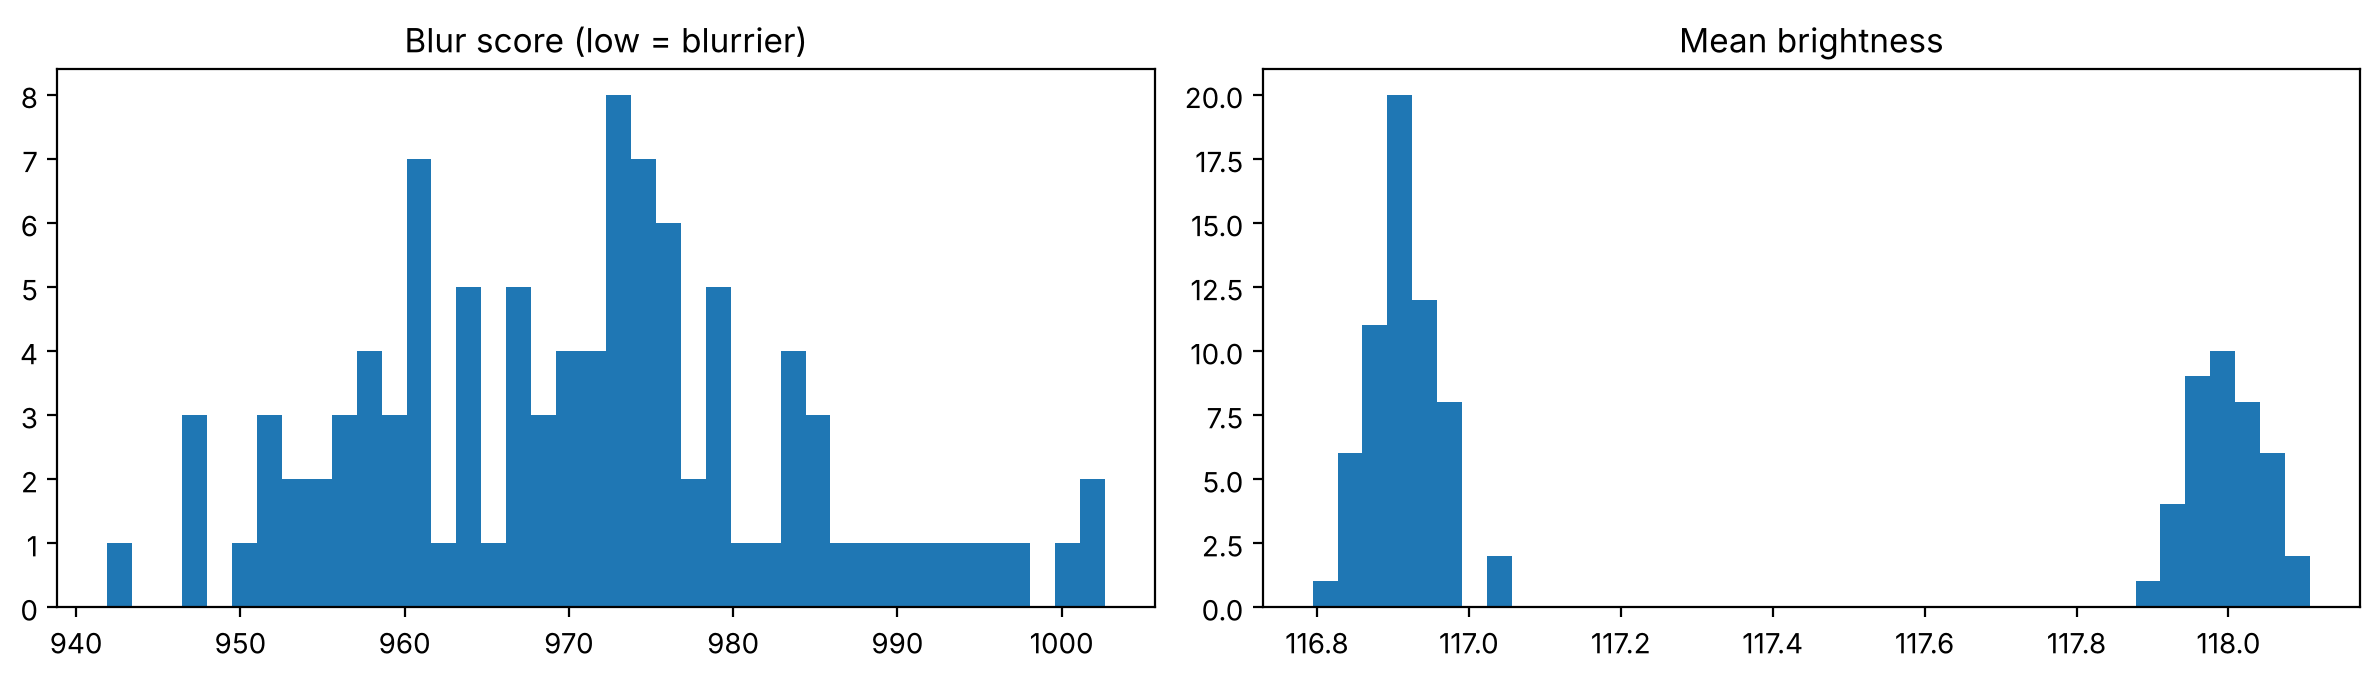

Frames kept after quality check: 100


In [8]:
if DATA_READY:
    stats_rows, unreadable = [], []
    for path in tqdm(list(labeled_df["image_path"]), desc="Checking images"):
        img = cv2.imread(path)
        if img is None:
            unreadable.append(path)
            continue
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        stats_rows.append({"image_path": path, "width": int(img.shape[1]), "height": int(img.shape[0]),
                           "blur_score": float(cv2.Laplacian(gray, cv2.CV_64F).var()),
                           "brightness": float(gray.mean())})

    quality_df = pd.DataFrame(stats_rows, columns=["image_path", "width", "height", "blur_score", "brightness"])
    print("Readable images:  ", len(quality_df))
    print("Unreadable images:", len(unreadable))

    if quality_df.empty:
        stop("No readable images.")
    else:
        display(quality_df[["width", "height", "blur_score", "brightness"]].describe().round(1))
        fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
        axes[0].hist(quality_df["blur_score"].clip(upper=quality_df["blur_score"].quantile(0.99)), bins=40)
        axes[0].set_title("Blur score (low = blurrier)")
        axes[1].hist(quality_df["brightness"], bins=40)
        axes[1].set_title("Mean brightness")
        plt.tight_layout()
        plt.show()
        labeled_df = labeled_df.merge(quality_df, on="image_path", how="inner").reset_index(drop=True)
        print("Frames kept after quality check:", len(labeled_df))
else:
    print('Skipped: an earlier step could not complete (see the STOPPED message above).')

## 9. Label distributions

Counted per **clip** (not per frame). DAiSEE is heavily imbalanced, especially for Frustration and Confusion.

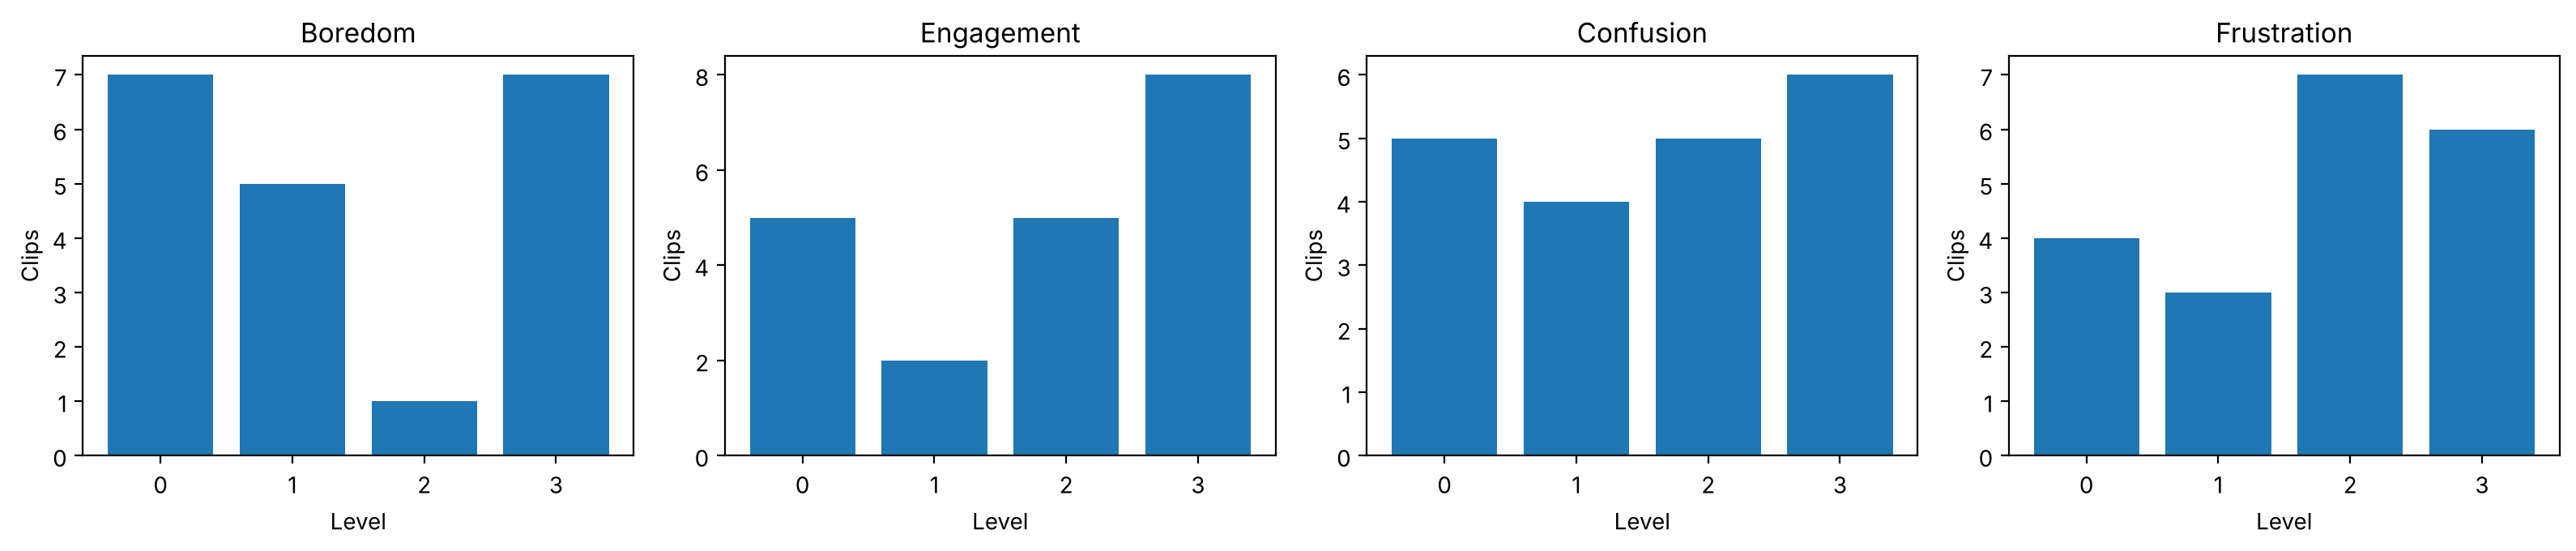

Clips per split:
split
train         12
test           4
validation     4

Engaged (Engagement >= 2) share: 0.65


In [9]:
if DATA_READY:
    clip_level = labeled_df.drop_duplicates("clip_id")
    fig, axes = plt.subplots(1, len(LABEL_COLUMNS), figsize=(4 * len(LABEL_COLUMNS), 3.5))
    for ax, col in zip(np.atleast_1d(axes), LABEL_COLUMNS):
        counts = clip_level[col].value_counts().reindex([0, 1, 2, 3], fill_value=0)
        ax.bar(counts.index.astype(str), counts.values)
        ax.set_title(col)
        ax.set_xlabel("Level")
        ax.set_ylabel("Clips")
    plt.tight_layout()
    plt.show()

    print("Clips per split:")
    print(clip_level["split"].value_counts().to_string())
    print("\nEngaged (Engagement >= 2) share:", round(float(clip_level["engaged_binary"].mean()), 3))
else:
    print('Skipped: an earlier step could not complete (see the STOPPED message above).')

## 10. Visualise raw labeled samples

Titles: clip ID and labels (`B` boredom, `E` engagement, `C` confusion, `F` frustration).

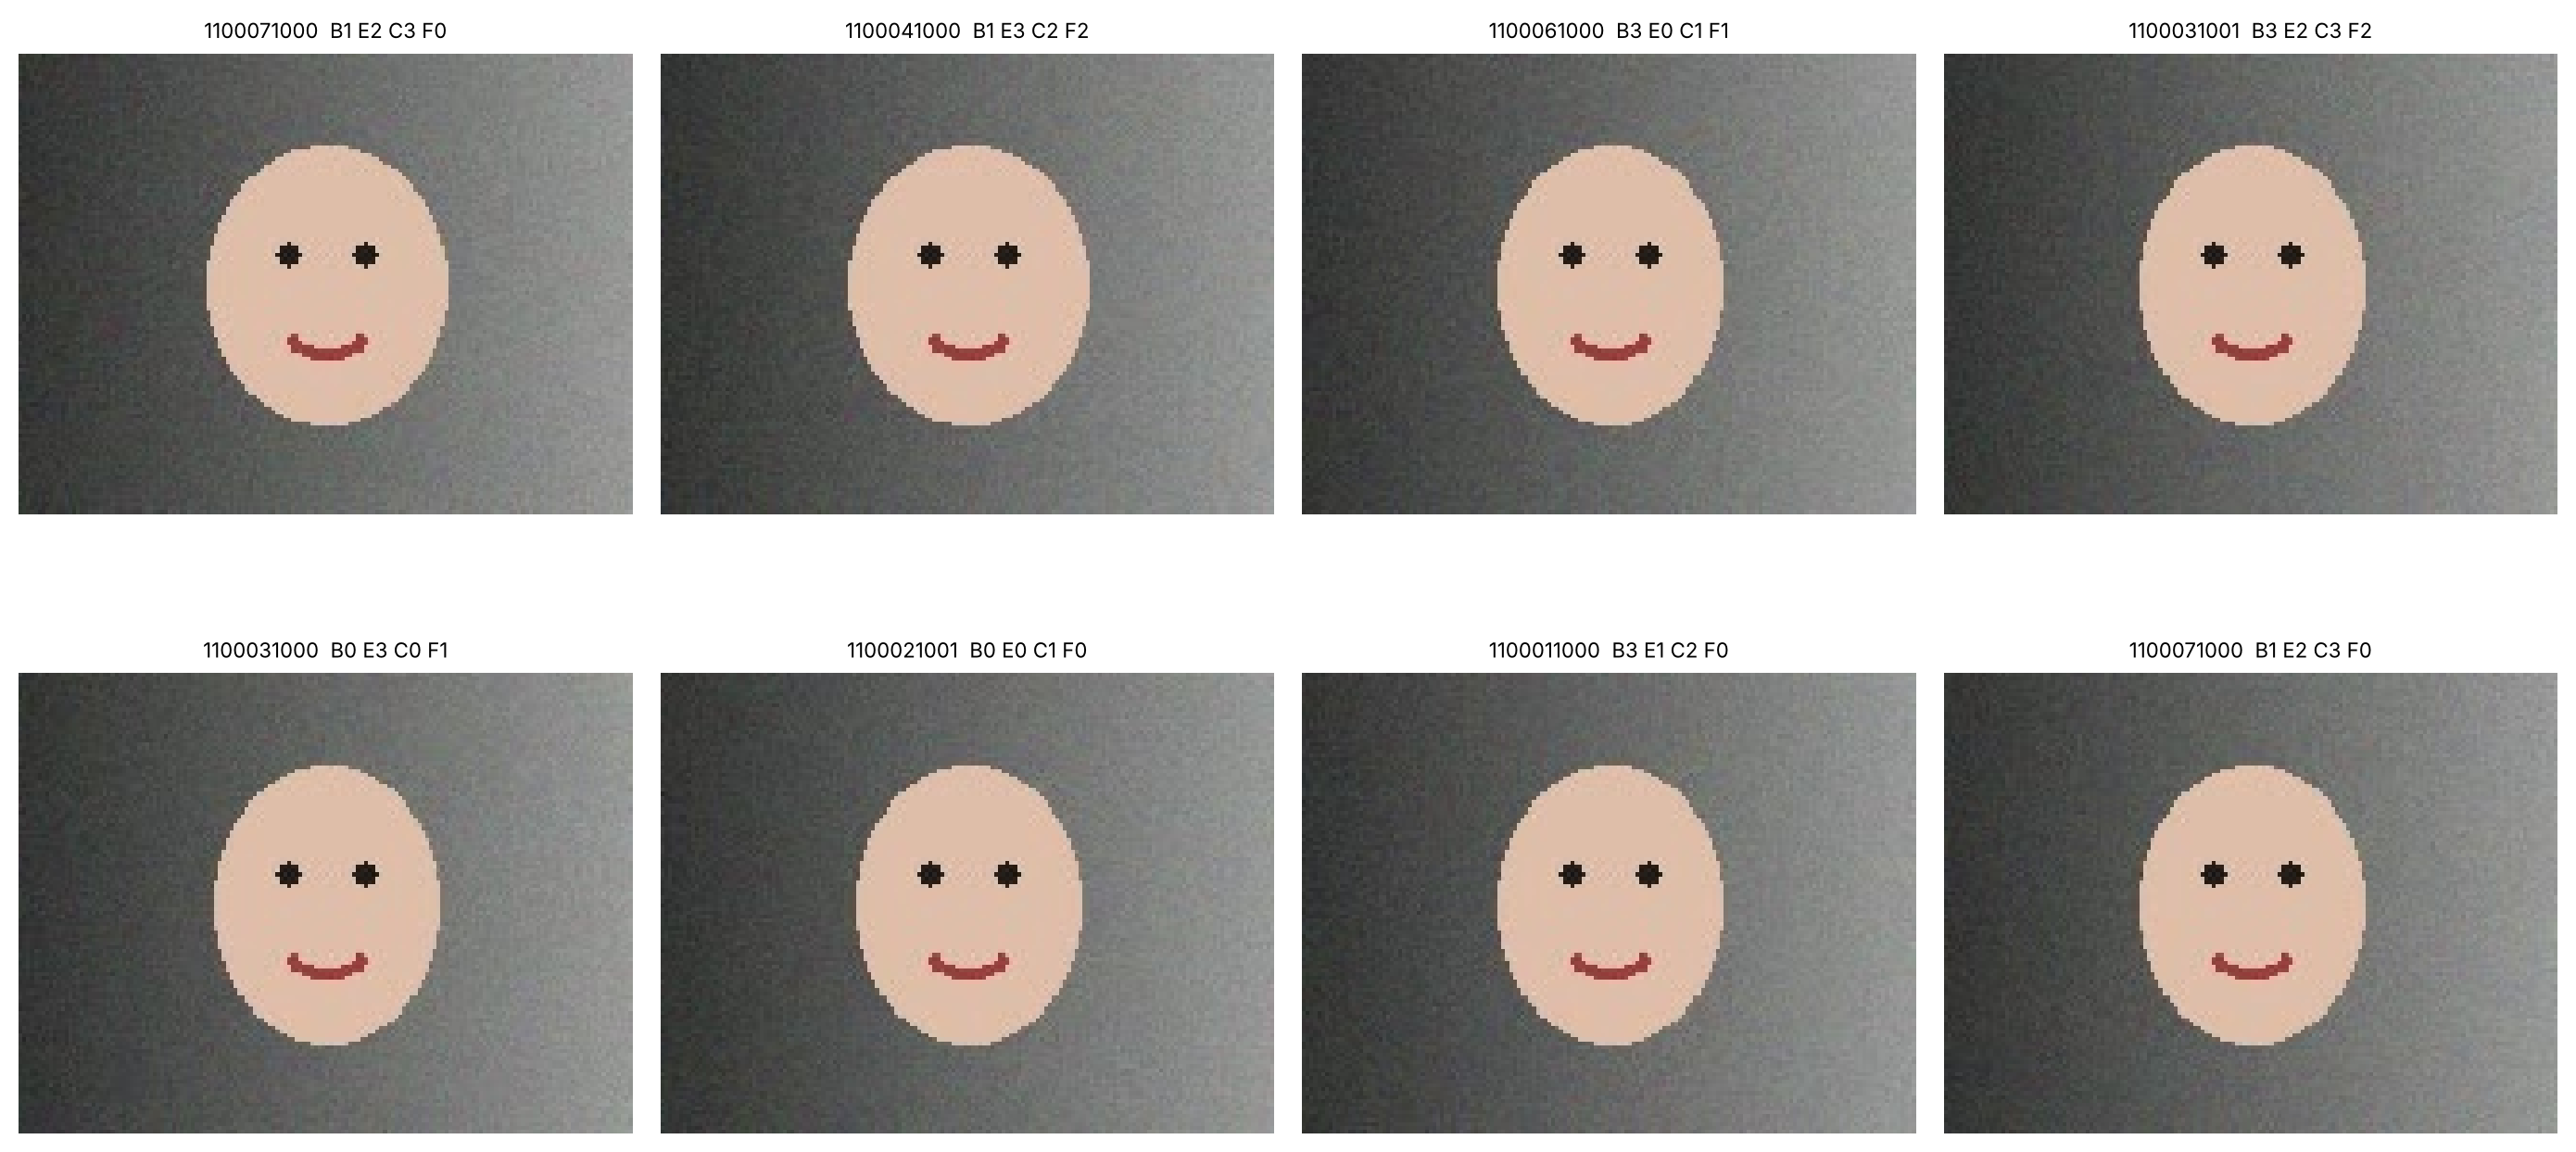

In [10]:
if DATA_READY:
    n_show = min(8, len(labeled_df))
    sample_rows = labeled_df.sample(n_show, random_state=SEED)
    fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
    axes = axes.flatten()
    for ax in axes:
        ax.axis("off")
    for ax, row in zip(axes, sample_rows.itertuples(index=False)):
        img = cv2.imread(row.image_path)
        if img is None:
            continue
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(f"{row.clip_id}  B{row.Boredom} E{row.Engagement} C{row.Confusion} F{row.Frustration}", fontsize=8)
    plt.tight_layout()
    plt.show()
else:
    print('Skipped: an earlier step could not complete (see the STOPPED message above).')

## 11. Face detection, crop, resize

OpenCV's Haar cascade finds the largest face; a margin is added, then the crop is resized to `IMAGE_SIZE`. If no face is found, the full frame is resized and `face_found` is `False` so you can filter later.

Images are stored as **RGB `uint8`** (0-255). Convert to `float32` in `[0, 1]` only when feeding a model.

In [11]:
if DATA_READY:
    face_cascade = None
    if DETECT_FACES:
        try:
            import glob
            cands = []
            if hasattr(cv2, "data"):
                cands.append(os.path.join(cv2.data.haarcascades, "haarcascade_frontalface_default.xml"))
            cands += glob.glob(os.path.join(os.path.dirname(cv2.__file__), "**", "haarcascade_frontalface_default.xml"), recursive=True)
            for cand in cands:
                if os.path.exists(cand):
                    cc = cv2.CascadeClassifier(cand)
                    if not cc.empty():
                        face_cascade = cc
                        break
        except Exception:
            face_cascade = None
        if face_cascade is None:
            print("Face cascade unavailable; using full-frame resize instead.")


    def crop_face(img_bgr):
        gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
        faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(60, 60))
        if len(faces) == 0:
            return img_bgr, False
        x, y, w, h = max(faces, key=lambda f: f[2] * f[3])
        px, py = int(w * FACE_PADDING), int(h * FACE_PADDING)
        x0, y0 = max(0, x - px), max(0, y - py)
        x1, y1 = min(img_bgr.shape[1], x + w + px), min(img_bgr.shape[0], y + h + py)
        return img_bgr[y0:y1, x0:x1], True


    def preprocess_image(path):
        img = cv2.imread(path)
        if img is None:
            return None, False
        found = False
        if face_cascade is not None:
            img, found = crop_face(img)
        img = cv2.resize(img, IMAGE_SIZE, interpolation=cv2.INTER_AREA)
        return cv2.cvtColor(img, cv2.COLOR_BGR2RGB), found


    images, kept_idx, face_flags, errors = [], [], [], []
    for i, path in enumerate(tqdm(list(labeled_df["image_path"]), desc="Preprocessing")):
        try:
            arr, found = preprocess_image(path)
        except Exception as exc:
            errors.append({"image_path": path, "error": str(exc)})
            continue
        if arr is None:
            errors.append({"image_path": path, "error": "could not read image"})
            continue
        images.append(arr)
        kept_idx.append(i)
        face_flags.append(found)

    if not images:
        stop("No images were preprocessed successfully.")
    else:
        proc_df = labeled_df.iloc[kept_idx].reset_index(drop=True).copy()
        proc_df["face_found"] = face_flags
        X = np.stack(images).astype(np.uint8)
        y = proc_df[LABEL_COLUMNS].to_numpy(dtype=np.int64)
        print("Image tensor:", X.shape, X.dtype)
        print("Label matrix:", y.shape, "columns:", LABEL_COLUMNS)
        print("Memory (MB): ", round(X.nbytes / 1e6, 1))
        print("Face detected in", round(100 * float(np.mean(face_flags)), 1), "% of frames")
        print("Preprocessing failures:", len(errors))
else:
    print('Skipped: an earlier step could not complete (see the STOPPED message above).')

Face cascade unavailable; using full-frame resize instead.


Preprocessing:   0%|          | 0/100 [00:00<?, ?it/s]

Preprocessing: 100%|██████████| 100/100 [00:00<00:00, 3955.21it/s]

Image tensor: (100, 224, 224, 3) uint8
Label matrix: (100, 4) columns: ['Boredom', 'Engagement', 'Confusion', 'Frustration']
Memory (MB):  15.1
Face detected in 0.0 % of frames
Preprocessing failures: 0


## 12. Preview preprocessed images

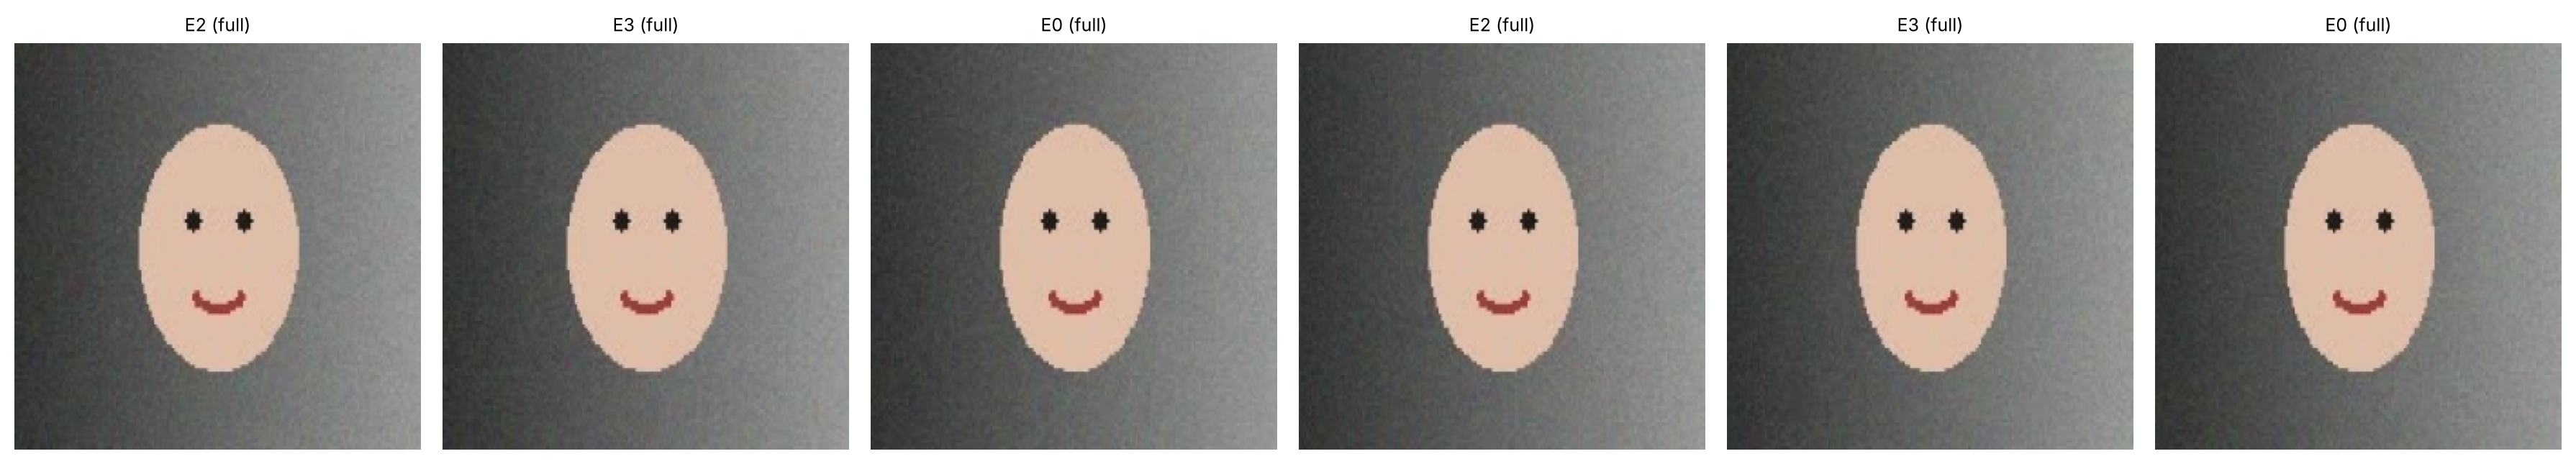

In [12]:
if DATA_READY:
    n = min(6, len(X))
    pick = np.random.RandomState(SEED).choice(len(X), n, replace=False)
    fig, axes = plt.subplots(1, n, figsize=(3 * n, 3.3))
    for ax, i in zip(np.atleast_1d(axes), pick):
        ax.imshow(X[i])
        tag = "face" if proc_df.loc[i, "face_found"] else "full"
        ax.set_title(f"E{y[i, 1]} ({tag})", fontsize=9)
        ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print('Skipped: an earlier step could not complete (see the STOPPED message above).')

## 13. Subject-independent train / validation / test split

Frames from the same video or person look nearly identical, so a random frame-level split leaks information and inflates accuracy. This cell:

1. Uses the **official DAiSEE split** when train, validation and test are all present.
2. Otherwise splits 70/15/15 **by person** (`subject_id`), falling back to clip groups if there are fewer than 3 people.

Then it verifies that no person appears in more than one split.

In [13]:
if DATA_READY:
    def grouped_split(df, group_col, fractions=(0.70, 0.15), seed=SEED):
        groups = np.array(sorted(df[group_col].astype(str).unique()))
        np.random.RandomState(seed).shuffle(groups)
        n = len(groups)
        mapping = {}
        if n < 3:
            for g in groups:
                mapping[g] = "train"
            print(f"Only {n} group(s); everything goes to train.")
        else:
            n_train = max(1, int(round(n * fractions[0])))
            n_val = max(1, int(round(n * fractions[1])))
            if n_train + n_val >= n:
                n_train, n_val = n - 2, 1
            for k, g in enumerate(groups):
                mapping[g] = "train" if k < n_train else ("validation" if k < n_train + n_val else "test")
        return df[group_col].astype(str).map(mapping)


    official_ok = {"train", "validation", "test"}.issubset(set(proc_df["split"]))
    if official_ok:
        proc_df["final_split"] = proc_df["split"]
        print("Using the official DAiSEE splits.")
    else:
        group_col = "subject_id" if proc_df["subject_id"].nunique() >= 3 else "clip_id"
        print(f"Official splits incomplete in this sample; splitting by {group_col}.")
        proc_df["final_split"] = grouped_split(proc_df, group_col)

    print(proc_df["final_split"].value_counts().to_string())

    subjects = {s: set(proc_df.loc[proc_df["final_split"] == s, "subject_id"]) for s in ["train", "validation", "test"]}
    overlap = {"train/validation": len(subjects["train"] & subjects["validation"]),
               "train/test": len(subjects["train"] & subjects["test"]),
               "validation/test": len(subjects["validation"] & subjects["test"])}
    print("Subjects shared between splits:", overlap)
    if any(overlap.values()):
        print("Warning: some people appear in more than one split. Review before training.")
else:
    print('Skipped: an earlier step could not complete (see the STOPPED message above).')

Using the official DAiSEE splits.
final_split
train         60
test          20
validation    20
Subjects shared between splits: {'train/validation': 0, 'train/test': 0, 'validation/test': 0}


## 14. Class weights (training split only)

Per label dimension, `n / (k * count)` over the classes present in training. Use them in your loss to counter imbalance. Absent classes get `0.0`.

In [14]:
if DATA_READY:
    train_mask = (proc_df["final_split"] == "train").to_numpy()
    class_weights = {}
    for j, col in enumerate(LABEL_COLUMNS):
        vals = y[train_mask, j]
        if len(vals) == 0:
            continue
        counts = np.bincount(vals, minlength=4)[:4]
        present = int((counts > 0).sum())
        class_weights[col] = {int(c): (round(float(len(vals) / (present * counts[c])), 4) if counts[c] > 0 else 0.0)
                              for c in range(4)}
    print(json.dumps(class_weights, indent=2))
else:
    print('Skipped: an earlier step could not complete (see the STOPPED message above).')

{
  "Boredom": {
    "0": 0.75,
    "1": 1.0,
    "2": 3.0,
    "3": 0.75
  },
  "Engagement": {
    "0": 0.75,
    "1": 3.0,
    "2": 1.5,
    "3": 0.6
  },
  "Confusion": {
    "0": 1.5,
    "1": 1.5,
    "2": 0.6,
    "3": 1.0
  },
  "Frustration": {
    "0": 1.5,
    "1": 1.0,
    "2": 0.75,
    "3": 1.0
  }
}


## 15. Save outputs

Compressed `.npz` arrays per split (`X` as `uint8`, `y` columns in `LABEL_COLUMNS` order), CSV manifests, class weights and the run config.

Add `emotionsense_outputs/`, `demo_DAiSEE/` and the dataset folder to `.gitignore` before pushing to GitHub.

In [15]:
if DATA_READY:
    for split_name in ["train", "validation", "test"]:
        mask = (proc_df["final_split"] == split_name).to_numpy()
        if mask.sum() == 0:
            print("Skipping empty split:", split_name)
            continue
        np.savez_compressed(
            OUTPUT_DIR / f"{split_name}.npz",
            X=X[mask], y=y[mask],
            clip_ids=proc_df.loc[mask, "clip_id"].to_numpy().astype(str),
            subject_ids=proc_df.loc[mask, "subject_id"].to_numpy().astype(str),
            label_columns=np.array(LABEL_COLUMNS),
        )
        print(f"Saved {split_name}.npz  X={X[mask].shape}")

    manifest_cols = ["image_path", "clip_id", "subject_id", "final_split", "frame_no", "source", "face_found",
                     "width", "height", "blur_score", "brightness"] + LABEL_COLUMNS + ["engaged_binary"]
    proc_df[manifest_cols].to_csv(OUTPUT_DIR / "frame_manifest.csv", index=False)
    quality_df.to_csv(OUTPUT_DIR / "image_quality_report.csv", index=False)
    if errors:
        pd.DataFrame(errors).to_csv(OUTPUT_DIR / "preprocessing_errors.csv", index=False)
    if failed_videos:
        pd.DataFrame({"video_path": failed_videos}).to_csv(OUTPUT_DIR / "failed_videos.csv", index=False)

    with open(OUTPUT_DIR / "class_weights.json", "w") as f:
        json.dump(class_weights, f, indent=2)
    config = {"label_columns": LABEL_COLUMNS, "frames_per_video": FRAMES_PER_VIDEO,
              "max_videos_per_split": MAX_VIDEOS_PER_SPLIT, "image_size": list(IMAGE_SIZE),
              "detect_faces": face_cascade is not None, "face_padding": FACE_PADDING, "seed": SEED,
              "used_official_split": bool(official_ok), "num_images": int(len(X))}
    with open(OUTPUT_DIR / "preprocessing_config.json", "w") as f:
        json.dump(config, f, indent=2)
    print("Saved outputs to:", OUTPUT_DIR.resolve())
    if IS_DEMO:
        print("(These outputs came from the synthetic demo data, not real DAiSEE.)")
else:
    print('Skipped: an earlier step could not complete (see the STOPPED message above).')

Saved train.npz  X=(60, 224, 224, 3)


Saved validation.npz  X=(20, 224, 224, 3)
Saved test.npz  X=(20, 224, 224, 3)
Saved outputs to: /tmp/claude-0/-home-claude/34ea60f0-0a28-5185-9fa7-6f370c5041d0/scratchpad/run/emotionsense_outputs_demo
(These outputs came from the synthetic demo data, not real DAiSEE.)


## 16. Loading the data for training (optional PyTorch example)

Runs only if PyTorch is installed; otherwise it is skipped.

In [16]:
if DATA_READY:
    try:
        import torch
        from torch.utils.data import Dataset, DataLoader

        class DAiSEEDataset(Dataset):
            def __init__(self, npz_path, label_index=1, transform=None):
                data = np.load(npz_path, allow_pickle=False)   # label_index: 1 = Engagement
                self.X = data["X"]
                self.y = data["y"][:, label_index]
                self.transform = transform

            def __len__(self):
                return len(self.X)

            def __getitem__(self, idx):
                img = torch.from_numpy(self.X[idx]).permute(2, 0, 1).float() / 255.0
                if self.transform is not None:
                    img = self.transform(img)
                return img, int(self.y[idx])

        train_path = OUTPUT_DIR / "train.npz"
        if train_path.exists():
            ds = DAiSEEDataset(train_path)
            xb, yb = next(iter(DataLoader(ds, batch_size=16, shuffle=True)))
            print("Batch images:", tuple(xb.shape), "| Batch labels:", tuple(yb.shape))
        else:
            print("train.npz not found.")
    except ImportError:
        print("PyTorch is not installed; skipping the Dataset example.")
else:
    print('Skipped: an earlier step could not complete (see the STOPPED message above).')

PyTorch is not installed; skipping the Dataset example.


## Summary

- Auto-detects DAiSEE, extracts frames from videos (or reuses existing frames), and joins them to the video-level labels by `ClipID`.
- Reports quality (blur, brightness), label imbalance and face-detection rate.
- Produces `uint8` 224x224 RGB arrays, subject-independent splits, class weights, manifests and a reproducible config.

**Caveats**
- Labels are **video-level**: every frame in a clip shares one label even if the person's state changes within it.
- Haar-cascade face detection misses non-frontal or poorly lit faces; consider MTCNN or MediaPipe for higher recall.
- No model is trained here and no accuracy is claimed. Next: a baseline classifier trained on `train.npz` and evaluated on the untouched `test.npz`.